# Consejo: ¿qué acción incentiva realmente el bono?

## Resumen
En dos acciones sintéticas, bono inmediato por volumen induce volume_chasing y beneficio neto esperado−22,5. Diferir90% de forma contingente al resultado induce prudent: utilidad8,55 frente8,25, margenIC0,30 ybeneficio neto firma8,95. El consejo puede abstenerse del proyecto(0): incremento frente a esa alternativa8,95, no31,45. No es estimación de efecto en ejecutivos reales.

## Modelo ysupuestos
Un bono base B=rate×volumen paga(1−f)B ahora yfB solo si no ocurre fracaso. Éxito pagaB; fracaso paga(1−f)B≥0. El agente neutral al riesgo elige laacción que maximiza B(1−f q)−esfuerzo. La firma evalúa beneficio operativo esperado menos bono esperado, sin imponer laacción objetivo.

El diseñador busca elmenor f del menú con margenIC≥0,05, participación≥0, implementación real yvalor neto firma no negativo. No maximiza beneficio delprincipal entre todos los contratos. Sin descuento, impuestos oaversión alriesgo; fracaso observable,no manipulable yconsecuencias contractuales ciertas.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
cfg=json.loads(Path('config.json').read_text())
summary=json.loads(Path('results/summary.json').read_text())
display(cfg)

{'bonus_rate': 0.1,
 'target': 'prudent',
 'required_margin': 0.05,
 'outside_utility': 0,
 'menu': [0, 0.25, 0.5, 0.75, 0.9, 1],
 'actions': [{'name': 'prudent',
   'volume': 100,
   'failure_probability': 0.05,
   'success_profit': 20,
   'failure_profit': -10,
   'effort_cost': 1},
  {'name': 'volume_chasing',
   'volume': 150,
   'failure_probability': 0.5,
   'success_profit': 35,
   'failure_profit': -50,
   'effort_cost': 0}],
 'units': 'synthetic money; manager effort expressed in utility-equivalent money; no discount, taxes or risk aversion',
 'hypothesis': 'a bounded contingent deferral contract implements prudent action with ICmargin>=0.05 and participation>=0; least deferral in menu'}

## Baseline ycontratos
La respuesta del agente usa desempate adverso alprincipal; no se declara implementación en una indiferencia favorable inventada. Participation incluye alternativa externa0. Probabilidades ybeneficios son supuestos sintéticos conocidos.

,deferred,implemented,ic_margin,target_utility,actual_principal_net,actual_bonus
0,0.00,volume_chasing,-6.00,9.000,-22.500,15.000
1,0.25,volume_chasing,-4.25,8.875,-20.625,13.125
2,0.50,volume_chasing,-2.50,8.750,-18.750,11.250
3,0.75,volume_chasing,-0.75,8.625,-16.875,9.375
4,0.90,prudent,0.30,8.550,8.950,9.550
5,1.00,prudent,1.00,8.500,9.000,9.500


{'deferred': 0.9,
 'target': {'name': 'prudent',
  'success_bonus': 10.0,
  'failure_bonus': 0.9999999999999998,
  'expected_bonus': 9.549999999999999,
  'manager_utility': 8.549999999999999,
  'gross_profit': 18.5,
  'net_profit': 8.950000000000001},
 'ic_margin': 0.29999999999999893,
 'participation_surplus': 8.549999999999999,
 'implemented': 'prudent'}

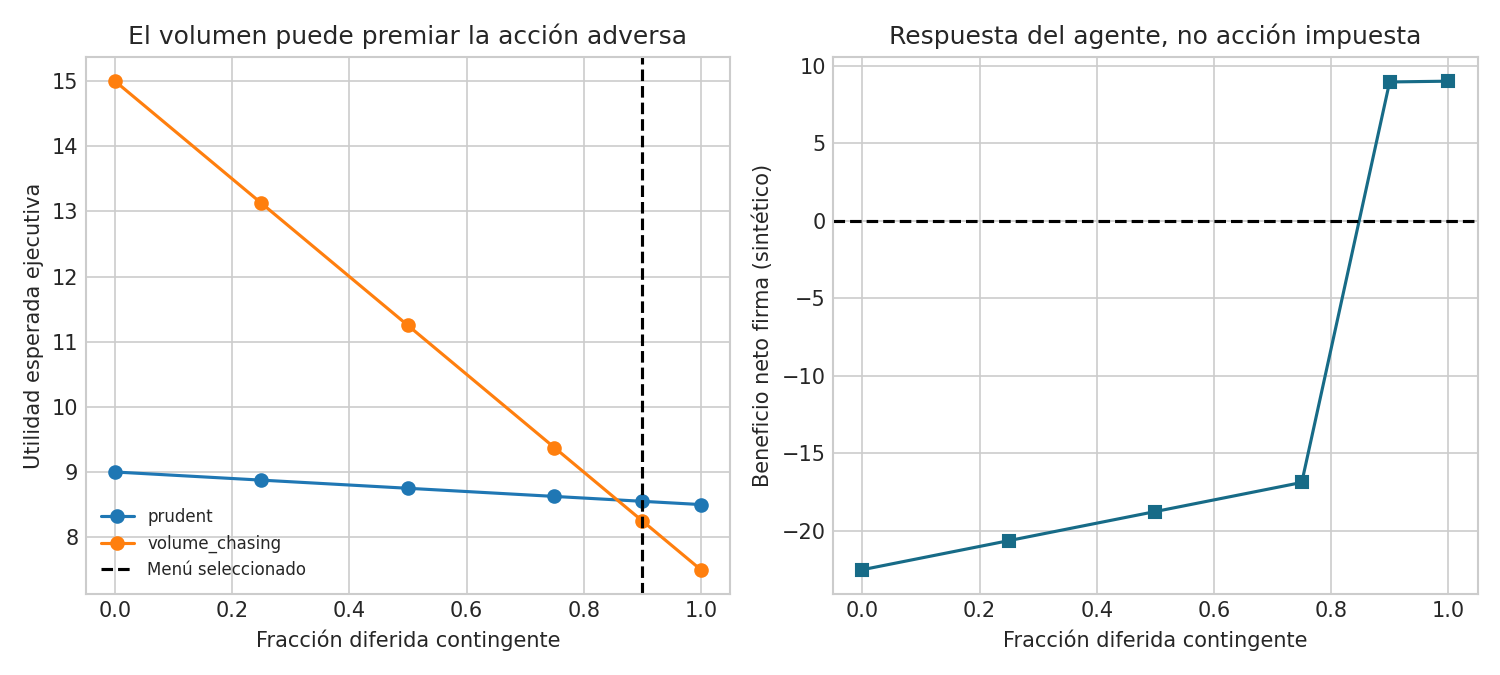

In [2]:
display(pd.read_csv('results/contracts.csv').round(4))
display(summary['selected'])
display(Image(filename='results/alignment.png'))

## Falsación ylímites
El mínimo continuo analítico para margen0,05 es6,05/7≈0,864286; elmenú elige0,9, no óptimo continuo. Con tope0,8 no es implementable. Una tercera acción omitida rompe laalineación yda beneficio neto−30,73. Los bonos siempre respetan responsabilidad limitada yse restan como transferencias del beneficio operativo.

In [3]:
display(pd.read_csv('results/sensitivity.csv'))
display(pd.read_csv('results/scaling.csv'))
display(summary['omitted_action_stress'])
assert summary['selected']['ic_margin']>=cfg['required_margin']
assert summary['selected']['implemented']==cfg['target']
assert summary['omitted_action_stress']['name']!=cfg['target']

,alternative_failure,feasible,deferred,ic_margin
0,0.1,False,NaN,NaN
1,0.3,False,NaN,NaN
2,0.5,True,0.9,0.3


,actions,median_seconds,repetitions,deferred
0,2,0.000030,5,0.9
1,20,0.000176,5,0.9
2,200,0.002827,5,0.9


{'name': 'unmodeled',
 'success_bonus': 30.0,
 'failure_bonus': 2.999999999999999,
 'expected_bonus': 29.73,
 'manager_utility': 29.73,
 'gross_profit': -1.0,
 'net_profit': -30.73}

## Decisión
Continuar solo como auditoría de diseño: diferimiento contingente ymedida de calidad deben contrastarse con acciones/probabilidades/costos reales aprobados. Ajustar menú si hayaversión alriesgo odescuento. Detener propuesta si no existe contratoIC/IR. No interpreta legalidad, obligación regulatoria ni aplicabilidad de malus/clawback. ComponenteS2 sintético, programa13 sinrecertificar.